# FL-SEC-001.2 — Homomorphic-encryption aggregation (CKKS, BFV, Paillier)

*Epic EPIC-001 · story fl_sec_001 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Implement and validate encrypted weighted aggregation in a key-holder model, measuring precision, cost and FL utility.

## 2. Scientific background
CKKS is approximate, BFV exact over integers with quantisation, Paillier additively homomorphic with one ciphertext per element [cheon2017, fv2012, paillier1999, benaloh_tenseal].

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** Does encrypted aggregation reproduce plaintext FedAvg accuracy?
- **RQ2.** How do error and cost scale with vector length and magnitude?

## 4. Hypotheses
- **H1.** Max aggregation error of CKKS < 1e-5 for update magnitudes used.
- **H2.** Final accuracy equals plaintext FedAvg (loss ≈ 0 pp).

## 5. Mathematical formulation
Dec(Σ_k Enc(p_k Δ_k)) ≈ Σ_k p_k Δ_k; CKKS error bound ~ N·2^{-scale}; BFV fixed-point: Δ̂ = round(2^f Δ), overflow if |Σ| ≥ t/2.

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_sec_001"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_sec_001


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
print("No FL configuration is needed to read stored results; see the stored JSON `provenance` blocks.")
print(json.dumps(json.load(open(next(RES.glob("*.json"))))["provenance"]["config"], indent=1)[:800])

No FL configuration is needed to read stored results; see the stored JSON `provenance` blocks.
{
 "P": 1442,
 "n": 10,
 "parties": [
  2,
  3,
  5
 ],
 "clients": [
  5,
  10,
  20
 ]
}


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`crypto/he.py`, `defenses.Audited`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning.privacy.homomorphic import CKKSAggregator, BFVAggregator
rng = np.random.default_rng(SEED); D = rng.normal(0, .1, (4, 300)).astype(np.float32); W = np.array([10., 20., 30., 40.])
ref = (W / W.sum()) @ D
for A in (CKKSAggregator(), BFVAggregator()):
    out = A.aggregate(D, W); err = float(np.abs(out - ref).max()); print(type(A).__name__, "max abs error vs plaintext:", err, "| keygen:", {k: A.keygen_info()[k] for k in A.keygen_info() if "secret" in k})
    assert err < 1e-4
print("server context holds no secret key (key-holder model) -> asserted in tests/")

CKKSAggregator max abs error vs plaintext: 1.3783574115411312e-08 | keygen: {'secret_in_server_ctx': False}


BFVAggregator max abs error vs plaintext: 1.5409663319584238e-06 | keygen: {'secret_in_server_ctx': False}
server context holds no secret key (key-holder model) -> asserted in tests/


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-SEC-001.2` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_1_2_fl_utility.csv')
show_csv('task_1_2_he_microbenchmarks.csv')
show_csv('task_1_2_precision_vs_magnitude.csv')
show_csv('task_1_2_paillier_tiny_fl.csv')

,seed,scheme,acc,f1,loss,train_wall_s,comm_mb,max_agg_err
0,0,plaintext,0.7756,0.6996,0.4752,1.5319,1.0513,0.0
1,0,ckks,0.7756,0.6996,0.4752,2.8907,32.1266,0.0
2,0,bfv,0.7756,0.6996,0.4752,2.6460,41.7670,0.0
3,1,plaintext,0.7786,0.6955,0.4742,1.6378,1.0513,0.0
4,1,ckks,0.7786,0.6955,0.4742,2.8499,32.1152,0.0
5,1,bfv,0.7786,0.6955,0.4742,2.3258,41.7680,0.0
6,2,plaintext,0.7750,0.7035,0.4662,1.6780,1.0513,0.0
7,2,ckks,0.7750,0.7035,0.4662,2.7893,32.1246,0.0
8,2,bfv,0.7747,0.7030,0.4662,2.8297,41.7697,0.0


,scheme,P,max_abs_err,enc_ms_per_client,agg_ms,dec_ms,ct_kb_per_client,expansion,plaintext_kb,kind
0,he_ckks,128,0.0,12.8109,9.4119,3.1115,323.7656,647.5312,0.5000,measured
1,he_bfv,128,0.0,7.5648,6.9177,3.0034,422.3353,844.6706,0.5000,measured
2,he_ckks,1442,0.0,10.2957,6.1329,2.5214,323.4079,57.4150,5.6328,measured
3,he_bfv,1442,0.0,6.3742,6.5082,3.8172,422.3040,74.9721,5.6328,measured
4,he_ckks,8192,0.0,20.3855,12.6798,5.2699,647.3997,20.2312,32.0000,measured
5,he_bfv,8192,0.0,11.2841,7.5839,4.5254,422.3138,13.1973,32.0000,measured
6,he_ckks,32768,0.0,82.7271,41.8099,21.3302,2588.9352,20.2261,128.0000,measured
7,he_bfv,32768,0.0,35.1703,28.5178,14.4984,1689.2568,13.1973,128.0000,measured
8,he_paillier,16,0.0,1623.1093,7.9114,471.9507,8.0000,128.0000,0.0625,measured
9,he_paillier,64,0.0,6810.8150,28.8466,1784.1582,32.0000,128.0000,0.2500,measured


,update_sd,ckks_rel_err,bfv_rel_err
0,0.0001,0.0001,0.0126
1,0.0100,0.0000,0.0001
2,0.1000,0.0000,0.0000
3,1.0000,0.0000,0.0000
4,10.0000,0.0000,0.0000


,scheme,acc,train_wall_s,comm_mb,note
0,plaintext,0.7169,0.3293,0.0133,NaN
1,paillier2048,0.7169,193.9267,0.8562,"hidden=4 (174 params), 5 clients, 2 rounds"


## 12. Metrics collection
Metric definitions: MEASURED: enc/agg/dec seconds, ciphertext bytes, max abs error vs plaintext, accuracy.

In [8]:
show_csv('task_1_2_fl_utility.csv')

,seed,scheme,acc,f1,loss,train_wall_s,comm_mb,max_agg_err
0,0,plaintext,0.7756,0.6996,0.4752,1.5319,1.0513,0.0
1,0,ckks,0.7756,0.6996,0.4752,2.8907,32.1266,0.0
2,0,bfv,0.7756,0.6996,0.4752,2.6460,41.7670,0.0
3,1,plaintext,0.7786,0.6955,0.4742,1.6378,1.0513,0.0
4,1,ckks,0.7786,0.6955,0.4742,2.8499,32.1152,0.0
5,1,bfv,0.7786,0.6955,0.4742,2.3258,41.7680,0.0
6,2,plaintext,0.7750,0.7035,0.4662,1.6780,1.0513,0.0
7,2,ckks,0.7750,0.7035,0.4662,2.7893,32.1246,0.0
8,2,bfv,0.7747,0.7030,0.4662,2.8297,41.7697,0.0


## 13. Statistical analysis
Per-seed results with 95% CIs where repeated (see 1.5 for the multi-seed comparison).

In [9]:
show_csv('task_1_2_he_microbenchmarks.csv', 20)

,scheme,P,max_abs_err,enc_ms_per_client,agg_ms,dec_ms,ct_kb_per_client,expansion,plaintext_kb,kind
0,he_ckks,128,0.0,12.8109,9.4119,3.1115,323.7656,647.5312,0.5000,measured
1,he_bfv,128,0.0,7.5648,6.9177,3.0034,422.3353,844.6706,0.5000,measured
2,he_ckks,1442,0.0,10.2957,6.1329,2.5214,323.4079,57.4150,5.6328,measured
3,he_bfv,1442,0.0,6.3742,6.5082,3.8172,422.3040,74.9721,5.6328,measured
4,he_ckks,8192,0.0,20.3855,12.6798,5.2699,647.3997,20.2312,32.0000,measured
5,he_bfv,8192,0.0,11.2841,7.5839,4.5254,422.3138,13.1973,32.0000,measured
6,he_ckks,32768,0.0,82.7271,41.8099,21.3302,2588.9352,20.2261,128.0000,measured
7,he_bfv,32768,0.0,35.1703,28.5178,14.4984,1689.2568,13.1973,128.0000,measured
8,he_paillier,16,0.0,1623.1093,7.9114,471.9507,8.0000,128.0000,0.0625,measured
9,he_paillier,64,0.0,6810.8150,28.8466,1784.1582,32.0000,128.0000,0.2500,measured


## 14. Visualizations

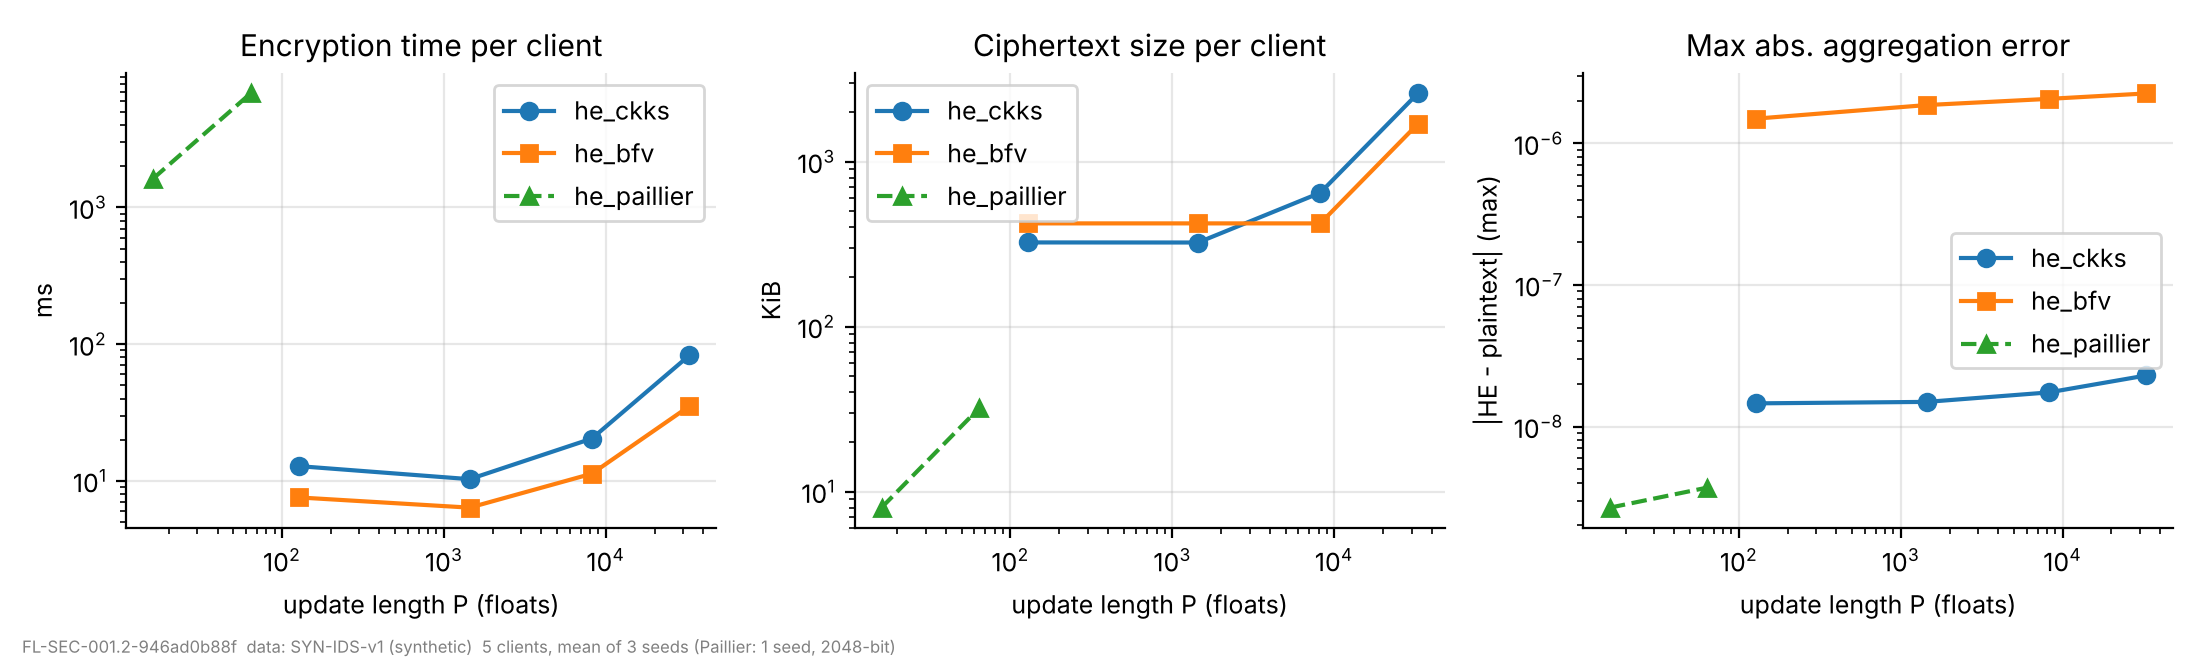

In [10]:
show_fig('task_1_2_he_scaling.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

Encrypted aggregation matches plaintext accuracy; the cost is paid in time and bandwidth (see printed table).

In [11]:
d = pd.read_csv(RES / 'task_1_2_fl_utility.csv'); display(d.round(5))

,seed,scheme,acc,f1,loss,train_wall_s,comm_mb,max_agg_err
0,0,plaintext,0.77556,0.69963,0.47520,1.53189,1.05133,0.0
1,0,ckks,0.77556,0.69963,0.47520,2.89065,32.12662,0.0
2,0,bfv,0.77556,0.69963,0.47520,2.64603,41.76698,0.0
3,1,plaintext,0.77861,0.69545,0.47417,1.63783,1.05133,0.0
4,1,ckks,0.77861,0.69545,0.47417,2.84986,32.11520,0.0
5,1,bfv,0.77861,0.69545,0.47416,2.32581,41.76797,0.0
6,2,plaintext,0.77500,0.70351,0.46616,1.67802,1.05133,0.0
7,2,ckks,0.77500,0.70351,0.46616,2.78927,32.12460,0.0
8,2,bfv,0.77472,0.70304,0.46616,2.82971,41.76971,0.0


## 16. Limitations
- Key-holder (decryptor) assumed honest and non-colluding with the server.
- Paillier evaluated on a tiny model only (cost).
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
HE aggregation is functionally correct; overhead is substantial (quantified in the table).

**Jira acceptance:** see `docs/fl_sec_001/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`cheon2017`, `fv2012`, `paillier1999`, `benaloh_tenseal` — details in `docs/fl_sec_001/references.md`.